# Bias-aware data assimilation on the Rijke tube

The regularized bias-aware EnKF (r-EnKF) of [Nóvoa, Racca & Magri (2023)](https://doi.org/10.1016/j.cma.2023.116502) on the Rijke tube of tutorial 20. The observations carry a bias that the low-order model does not have, and an echo state network (ESN) estimates the bias from the innovations, while the filter estimates the state and the parameters $\beta$ and $\tau$. Tutorial 16 introduces bias-aware data assimilation on the Van der Pol oscillator; `scripts/thermoacoustics/cmame2023` reproduces the paper.

In [1]:
from romda.utils import set_working_directories
data_folder, results_folder = set_working_directories('rijke/')[:2]

## 1. Truth and observations

The truth is the Rijke model with a linear bias added to its pressure, $p'_\mathrm{true} + 0.3\,p'_\mathrm{true} + 0.1\max|p'_\mathrm{true}|$, observed every 20 time steps from $t = 0.2$ s to $0.6$ s.

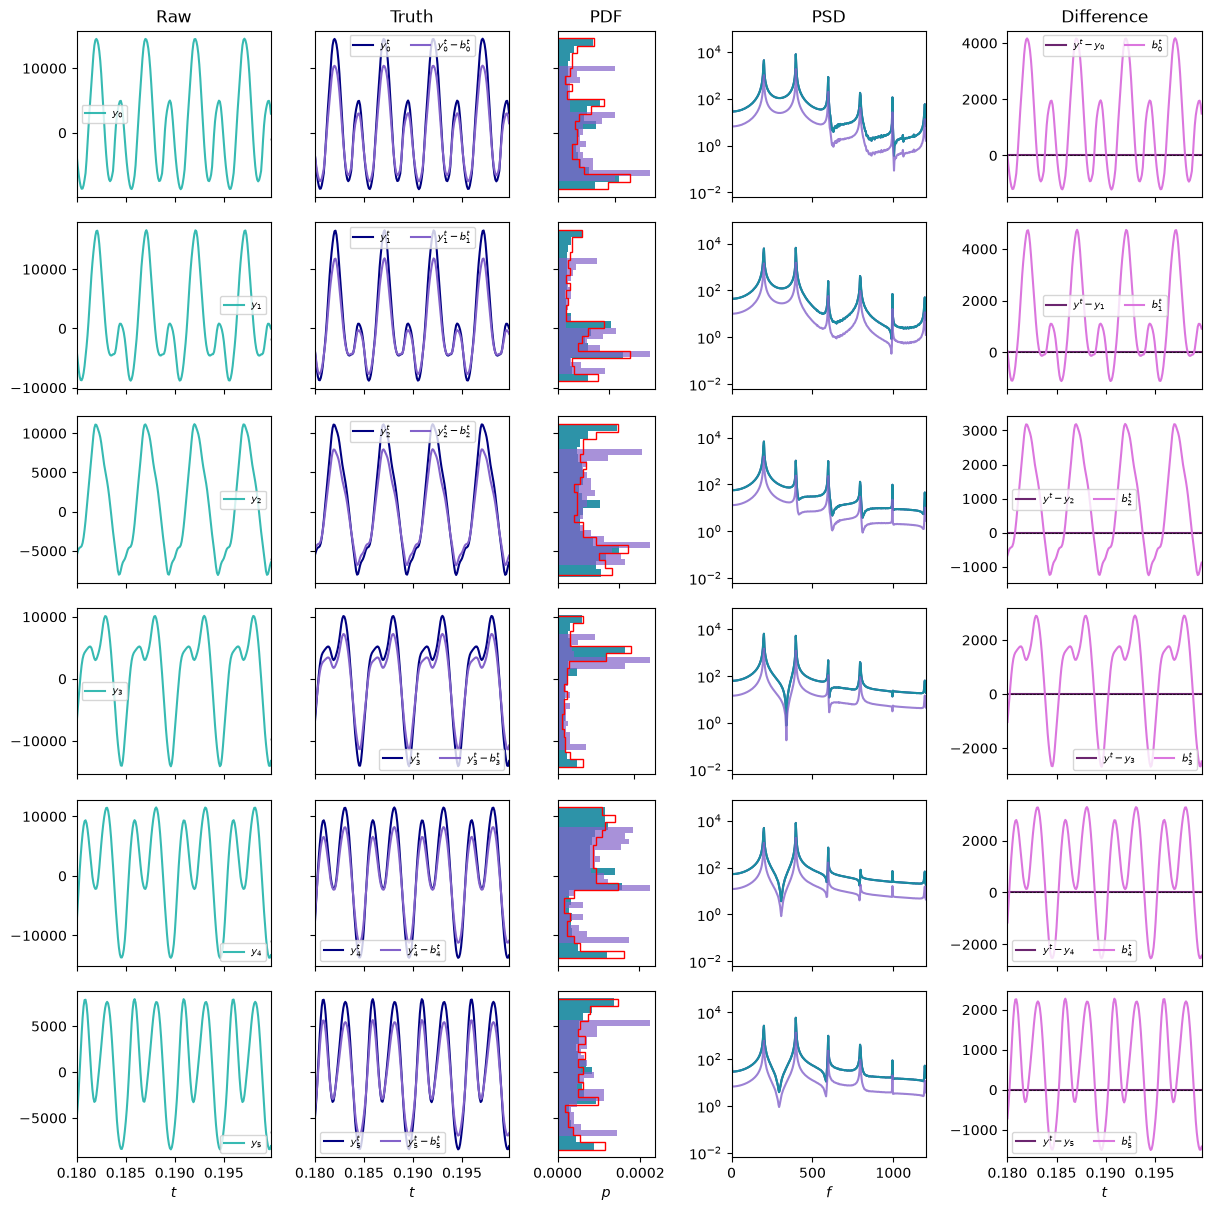

In [2]:
from romda.models.physical import Rijke
from romda.observations import Observations

truth = Observations(model=Rijke,
                     manual_bias='linear',
                     t_start=.2,
                     t_stop=.6,
                     Nt_obs=20)

truth.plot_truth(truth, f_max=1200, window=0.02, fig_width=12)

## 2. The ensemble

Ten members, with $\beta$ and $\tau$ drawn uniformly in the given ranges.

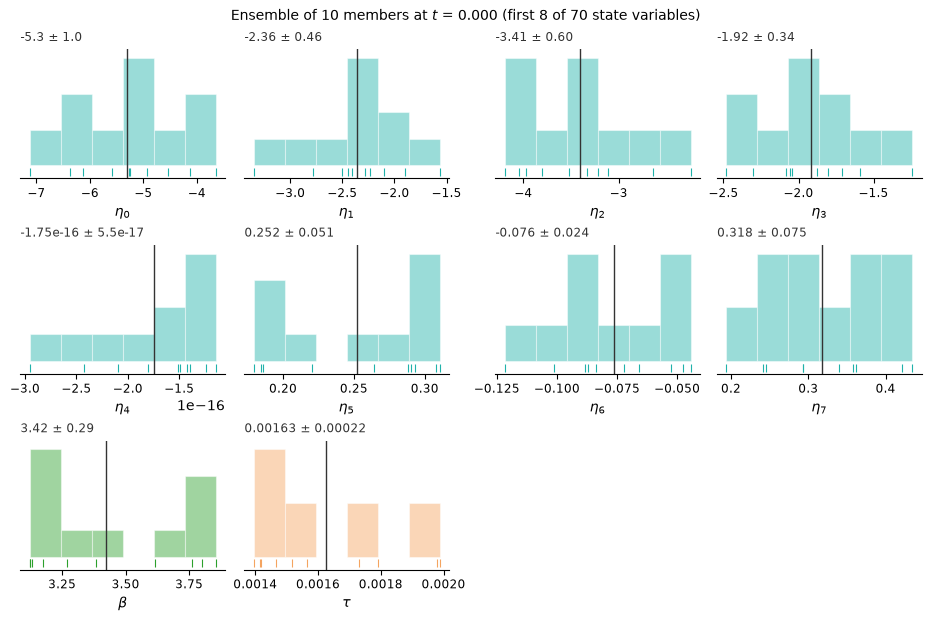

In [3]:
from romda.estimators import rBA_EnKF

ensemble = rBA_EnKF(parent_model=Rijke(dt=truth.dt),
                    bias_regularization=1.,
                    m=10,
                    std_phi=0.25,
                    std_alpha=dict(beta=[3., 4.],
                                   tau=[1e-3, 2e-3]),
                    distribution_alpha='uniform',
                    inflation=1.0,
                    inflation_factor_rejection=1.005,
                    )

ensemble.visualize_state()

## 3. The ESN bias estimator

The ESN is trained on the innovations of `L = 20` model realizations, with parameters spread around the prior, against the truth (`augment_data`). The first run trains it and stores it; later runs load it.

In [4]:
from romda.bias_estimators import ESN_bias
import numpy as np

training_data_filename = f"{results_folder}/ESN_train_data_rijke_{truth.name_bias}"

bias_estimator = ESN_bias(rom=ensemble.model,
                          reference_data=truth,
                          training_data_filename=training_data_filename,
                          # Training data generation options
                          augment_data=True,
                          biased_observations=False,
                          correlation_based_training=False,
                          L=20,
                          std_alpha=0.3,
                          # Training, validation and test times
                          t_val=0.02,
                          t_train=0.25,
                          t_test=0.06,
                          N_units=100,
                          N_wash=15,
                          upsample=2,
                          # Hyperparameter search ranges
                          rho_range=(0.2, 1.0),
                          tikh_range=[1e-16],
                          sigma_in_range=(np.log10(1e-5), np.log10(1e-2)),
                          plot_training=True,
                          N_ens=10,
                          )

## 4. Data assimilation

The reservoir of the ESN must be synchronized with the data before the first analysis. `run_da_loop(..., washout=True)` drives the network with the innovations of the `N_wash` network steps before the first observation, as in the paper. Without the washout, the bias forecast diverges and the filter rejects every analysis.

In [5]:
from romda.data_assimilation import run_da_loop

filter_ens = ensemble.copy()
filter_ens.bias = bias_estimator.copy()
filter_ens.regularization_factor = 1.

# Observation error covariance: a variance of 0.1 max|d|^2 for each observable
Cdd = np.diag(0.1 * np.ones(filter_ens.model.Nq)) * np.max(abs(truth.y_obs), axis=0) ** 2

filter_ens = run_da_loop(filter_ens, truth, Cdd=Cdd, washout=True, t_extra=10 * filter_ens.model.t_CR)
print(f'rejected analyses: {len(filter_ens.rejected_analysis.times)} of {len(truth.t_obs)}')

rejected analyses: 0 of 201


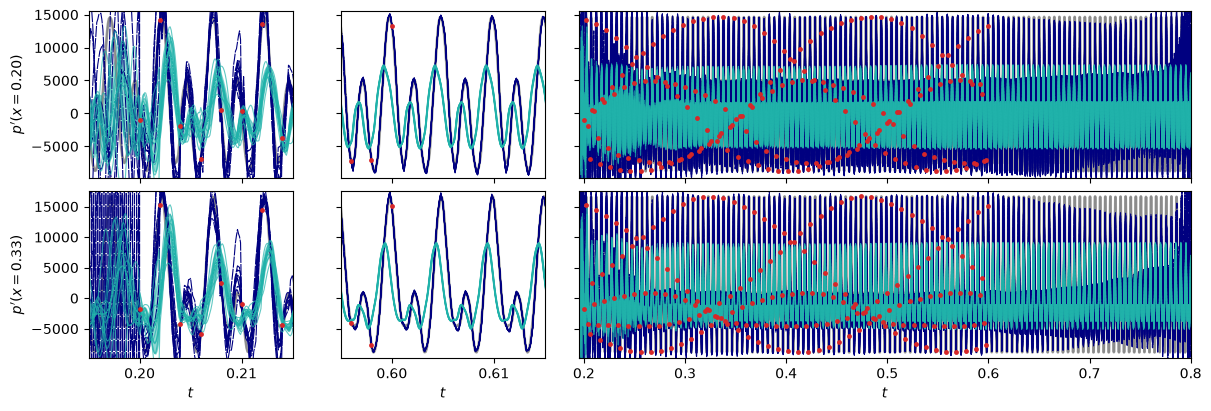

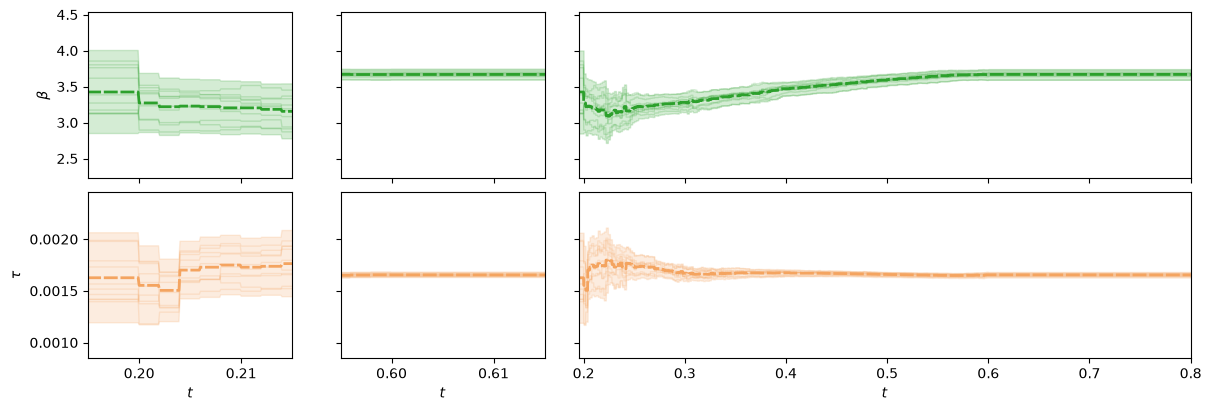

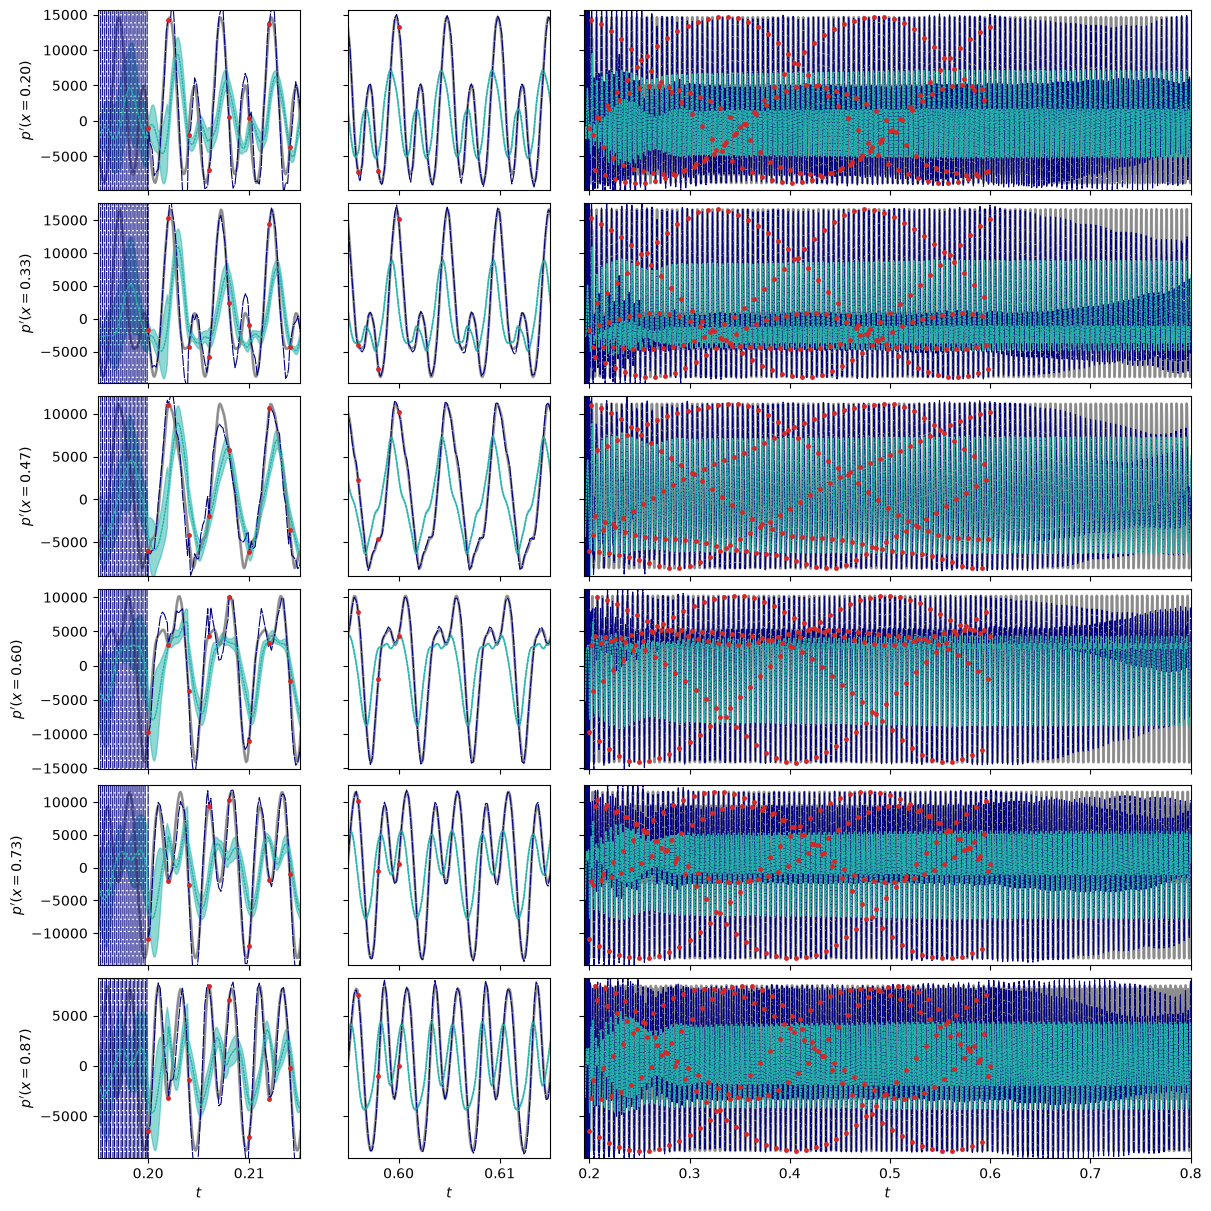

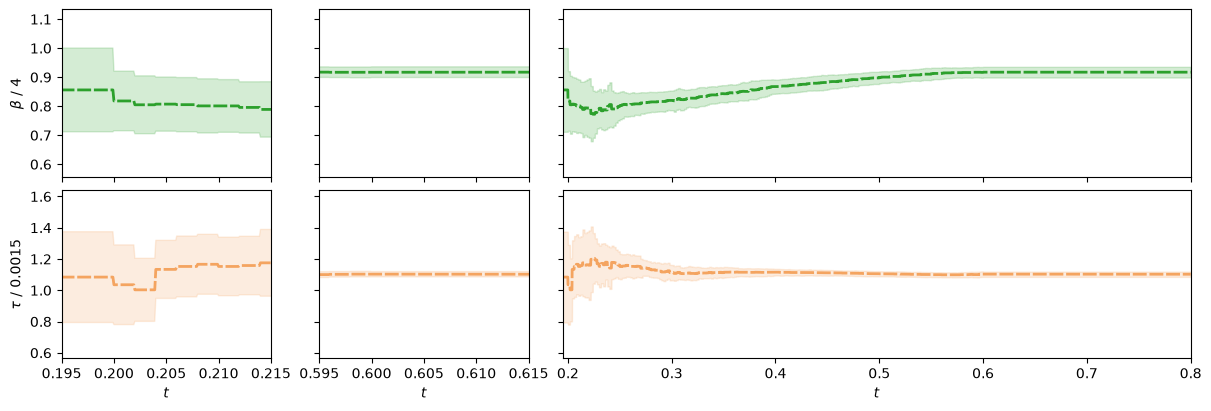

In [6]:
filter_ens.visualize_history(truth=truth, plot_members=True, dims=[0, 1])
filter_ens.visualize_history(truth=truth, plot_members=False, reference_a=truth.true_parameters)

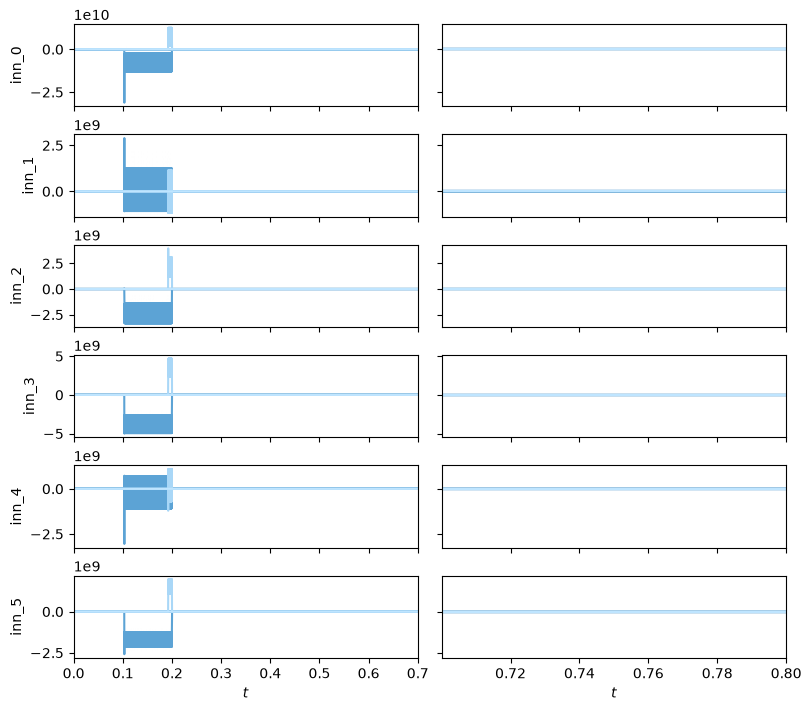

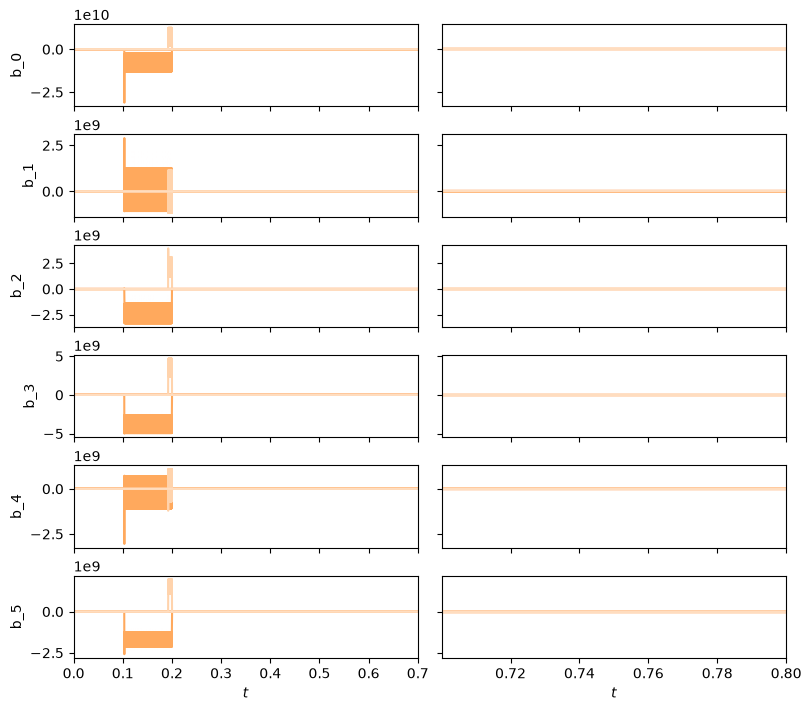

In [7]:
# The estimated bias and the innovations over the assimilation window
filter_ens.bias.visualize_bias_and_innovations(plot_members=True)

The bias-corrected estimate (model estimate plus the ESN bias) follows the truth, whereas the model estimate alone does not, because the observations carry a bias that the model does not have. The parameters settle by $t \approx 0.5$ s, with $\beta$ about 8 % below the value of the truth and $\tau$ 10 % above: the bias regularization sets how the misfit is shared between the parameters and the bias (tutorial 16).